<a href="https://colab.research.google.com/github/Ankita2410537/AI-LAB/blob/main/stroke_processed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os
import warnings

warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
print("==========================================")
print("       STROKE PREDICTION SYSTEM")
print("==========================================")

print("\nSelect your processed Stroke Dataset.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset uploaded!")

dataframes = {}

for filename, content in uploaded.items():

    if filename.lower().endswith(".csv"):
        dataframes[filename] = pd.read_csv(
            io.BytesIO(content)
        )

    elif filename.lower().endswith(".xlsx"):
        dataframes[filename] = pd.read_excel(
            io.BytesIO(content)
        )

    else:
        print("Unsupported file skipped:", filename)

if not dataframes:
    raise ValueError("Please upload a valid CSV or Excel file.")

print("\nUploaded Files:")

for filename, data in dataframes.items():
    print(filename, ":", data.shape)

print("\nUpload completed successfully!")

       STROKE PREDICTION SYSTEM

Select your processed Stroke Dataset.


Saving stroke_processed_5k.csv to stroke_processed_5k.csv

Uploaded Files:
stroke_processed_5k.csv : (5110, 11)

Upload completed successfully!


In [4]:
# ==========================================================
# DATASET PREPARATION
# ==========================================================

def prepare_target(data):

    data = data.copy()
    data.columns = data.columns.str.strip()

    if "stroke" not in data.columns:
        raise ValueError(
            "Dataset must contain a 'stroke' target column."
        )

    if "id" in data.columns:
        data.drop(columns=["id"], inplace=True)

    data.dropna(subset=["stroke"], inplace=True)

    target = data["stroke"]

    if not set(target.unique()).issubset({0, 1}):

        labels = target.astype(str).str.lower().str.strip()

        positive = {"yes", "stroke", "positive", "true", "1"}
        negative = {"no", "negative", "false", "0"}

        if not set(labels.unique()).issubset(positive | negative):
            raise ValueError("Target must contain binary stroke labels.")

        data["stroke"] = labels.map(
            lambda x: 1 if x in positive else 0
        )

    data["stroke"] = data["stroke"].astype(int)

    if data["stroke"].nunique() != 2:
        raise ValueError("Both stroke classes must be present.")

    return data


# Detect previously generated train/test files
train_files = [
    name for name in dataframes
    if "training" in name.lower()
]

test_files = [
    name for name in dataframes
    if "testing" in name.lower()
]

if train_files and test_files:

    train_df = prepare_target(dataframes[train_files[0]])
    test_df = prepare_target(dataframes[test_files[0]])

    if set(train_df.columns) != set(test_df.columns):
        raise ValueError("Training and testing columns do not match.")

    feature_columns = [
        col for col in train_df.columns if col != "stroke"
    ]

    X_train_raw = train_df[feature_columns]
    y_train = train_df["stroke"]

    X_test_raw = test_df[feature_columns]
    y_test = test_df["stroke"]

    print("Using uploaded training and testing datasets.")

else:

    # Use the first uploaded dataset
    df = prepare_target(next(iter(dataframes.values())))

    X = df.drop(columns=["stroke"])
    y = df["stroke"]

    if y.value_counts().min() < 2:
        raise ValueError("Each class needs at least two records.")

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    print("Dataset split into 80% training and 20% testing.")

# Align columns
X_test_raw = X_test_raw[X_train_raw.columns]

print("\nTraining Shape:", X_train_raw.shape)
print("Testing Shape:", X_test_raw.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

# ==========================================================
# TOTAL STROKE AND NON-STROKE COUNT
# ==========================================================

all_labels = pd.concat([
    pd.Series(y_train),
    pd.Series(y_test)
])

stroke_count = (all_labels == 1).sum()
non_stroke_count = (all_labels == 0).sum()

print("\n======================================")
print("       TOTAL STROKE ANALYSIS")
print("======================================")

print("Total Patients:", len(all_labels))
print("Total Stroke Cases:", stroke_count)
print("Total Non-Stroke Cases:", non_stroke_count)

print("Stroke Percentage:",
      round(stroke_count / len(all_labels) * 100, 2), "%")

print("======================================")

Dataset split into 80% training and 20% testing.

Training Shape: (4088, 10)
Testing Shape: (1022, 10)

Training Target Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Target Distribution:
stroke
0    972
1     50
Name: count, dtype: int64

Testing Target Distribution:
stroke
0    972
1     50
Name: count, dtype: int64

       TOTAL STROKE ANALYSIS
Total Patients: 5110
Total Stroke Cases: 249
Total Non-Stroke Cases: 4861
Stroke Percentage: 4.87 %


In [5]:
# Identify feature types
numeric_features = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessor
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit and transform
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Convert sparse matrices
if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()

if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train, dtype=int)
y_test = np.asarray(y_test, dtype=int)

print("Preprocessing completed successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Preprocessing completed successfully!
Training Features: (4088, 10)
Testing Features: (1022, 10)


In [6]:
print("\nTraining Logistic Regression...")

lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

print("Logistic Regression completed!")


Training Logistic Regression...
Logistic Regression completed!


In [7]:
print("\nTraining Decision Tree...")

dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:, 1]

print("Decision Tree completed!")


Training Decision Tree...
Decision Tree completed!


In [8]:
print("\nTraining Random Forest...")

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print("Random Forest completed!")


Training Random Forest...
Random Forest completed!


In [9]:
print("\nTraining Support Vector Machine...")

svm = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)
svm_prob = svm.predict_proba(X_test)[:, 1]

print("SVM completed!")


Training Support Vector Machine...
SVM completed!


In [10]:
print("\nTraining Artificial Neural Network...")

# Calculate class weights
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

# Build ANN with BatchNormalization for better stability
ann = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

# Compile ANN with comprehensive metrics
ann.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train ANN and save history to find best threshold on validation set
history = ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

# Get validation probabilities to find the optimal threshold
# (Using a separate validation split or extracting validation predictions)
val_split_idx = int(len(X_train) * 0.8)
X_val, y_val = X_train[val_split_idx:], y_train[val_split_idx:]
val_probs = ann.predict(X_val, verbose=0).ravel()

# Find threshold that maximizes F1-score on validation set
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"\nOptimal Decision Threshold found: {best_threshold:.4f}")

# Predict on Test Set using the optimized threshold
ann_prob = ann.predict(X_test, verbose=0).ravel()
ann_pred = (ann_prob >= best_threshold).astype(int)

print("Artificial Neural Network completed with Optimized Threshold!")


Training Artificial Neural Network...
Epoch 1/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.5774 - auc: 0.6598 - loss: 0.7294 - precision: 0.0687 - recall: 0.6447 - val_accuracy: 0.8203 - val_auc: 0.8488 - val_loss: 0.5736 - val_precision: 0.2024 - val_recall: 0.7234
Epoch 2/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6431 - auc: 0.7720 - loss: 0.5889 - precision: 0.0937 - recall: 0.7697 - val_accuracy: 0.8191 - val_auc: 0.8519 - val_loss: 0.4950 - val_precision: 0.2047 - val_recall: 0.7447
Epoch 3/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6737 - auc: 0.7920 - loss: 0.5576 - precision: 0.0990 - recall: 0.7434 - val_accuracy: 0.8056 - val_auc: 0.8540 - val_loss: 0.4801 - val_precision: 0.1989 - val_recall: 0.7872
Epoch 4/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6942 - auc: 0.7956 - loss: 0.5443 - precision: 0.1030 - recall: 0.7237 - val_accuracy: 0.7738 - val_auc: 0.8519 - val_loss: 0.4999 - val_precision: 0.1806 - val_recall: 

In [11]:

# ==========================================================
# PERFORMANCE EVALUATION OF FIVE ML MODELS
# ==========================================================

models = {
    "Logistic Regression": (lr_pred, lr_prob),
    "Decision Tree": (dt_pred, dt_prob),
    "Random Forest": (rf_pred, rf_prob),
    "SVM": (svm_pred, svm_prob),
    "ANN": (ann_pred, ann_prob)
}

results = {}

for name, (pred, prob) in models.items():

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # Calculate performance metrics
    results[name] = {

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),

        "F1-Score": f1_score(
            y_test, pred, zero_division=0
        ),

        "AUC-ROC": roc_auc_score(y_test, prob),

        "Strokes Found": tp,

        "Non-Strokes Found": tn
    }

# Convert results into DataFrame
results_df = pd.DataFrame(results).T

# Display comparative results
print("\n==============================================")
print("       FIVE MODEL PERFORMANCE EVALUATION")
print("==============================================")

display(results_df.round(4))

# Save performance results
results_df.to_csv(
    "model_performance_results.csv"
)

print("\nPerformance results saved successfully!")



       FIVE MODEL PERFORMANCE EVALUATION


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Strokes Found,Non-Strokes Found
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387,40.0,728.0
Decision Tree,0.7613,0.1057,0.52,0.1757,0.6727,26.0,752.0
Random Forest,0.9501,0.0000,0.00,0.0000,0.7904,0.0,971.0
SVM,0.7358,0.1181,0.68,0.2012,0.7856,34.0,718.0
ANN,0.7857,0.1404,0.66,0.2316,0.8066,33.0,770.0



Performance results saved successfully!


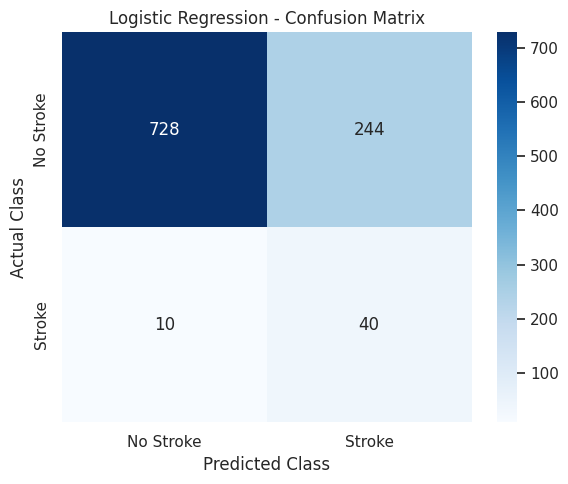

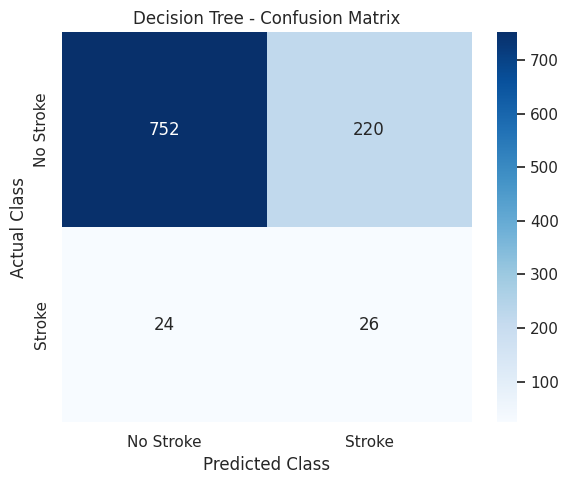

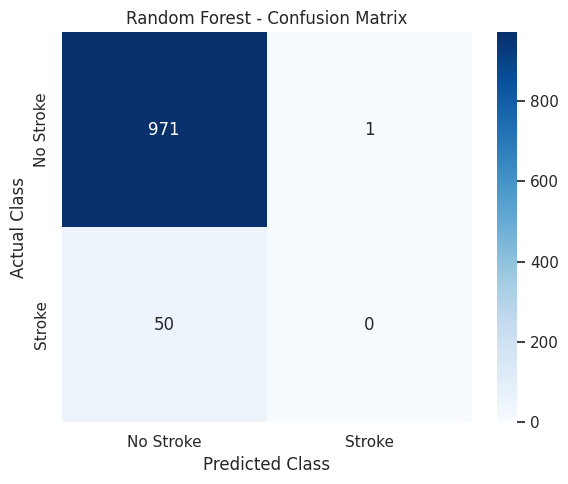

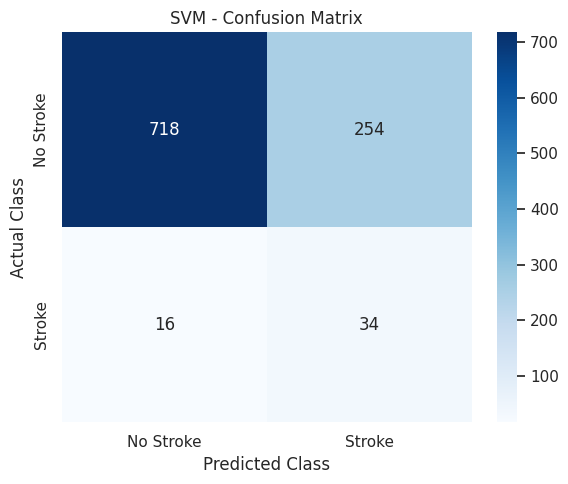

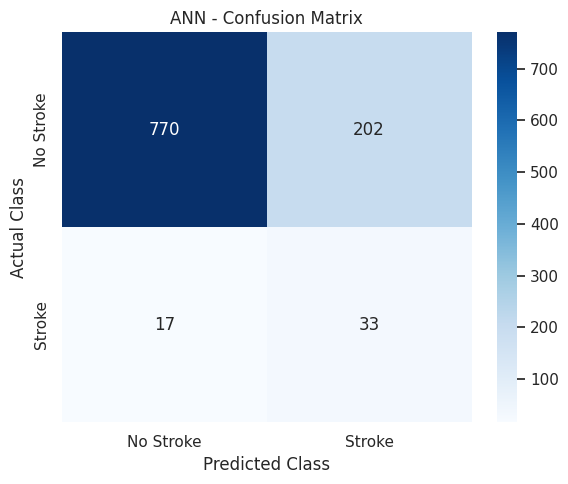

All five confusion matrices generated!


In [12]:
# ==========================================================
# CONFUSION MATRICES
# ==========================================================

for name, (pred, prob) in models.items():

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()

    filename = (
        "Confusion_Matrix_" +
        name.replace(" ", "_") +
        ".png"
    )

    plt.savefig(filename, dpi=300)
    plt.show()
    plt.close()

print("All five confusion matrices generated!")

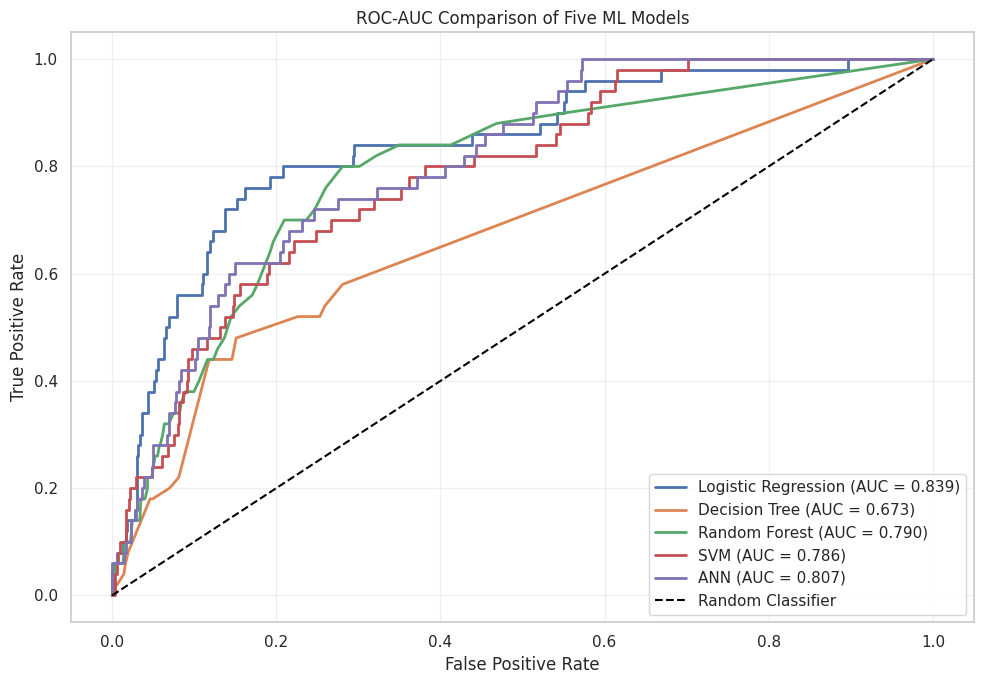

Combined ROC-AUC curve generated!


In [13]:
# ==========================================================
# ROC-AUC CURVE COMPARISON
# ==========================================================

plt.figure(figsize=(10, 7))

for name, (pred, prob) in models.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        prob
    )

    auc_value = roc_auc_score(
        y_test,
        prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.title("ROC-AUC Comparison of Five ML Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Combined_ROC_Curve.png",
    dpi=300
)

plt.show()

print("Combined ROC-AUC curve generated!")

In [14]:

# ==========================================================
# TOP THREE MODEL SELECTION WITH STROKE COUNTS
# ==========================================================

# Calculate weighted ranking score
results_df["Ranking Score"] = (
    0.40 * results_df["Recall"] +
    0.30 * results_df["F1-Score"] +
    0.30 * results_df["AUC-ROC"]
)

# Calculate correctly identified stroke and non-stroke cases
stroke_found = {}
non_stroke_found = {}

for name, (pred, prob) in models.items():

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    stroke_found[name] = tp
    non_stroke_found[name] = tn

# Add two new columns
results_df["Strokes Found"] = pd.Series(stroke_found)

results_df["Non-Strokes Found"] = pd.Series(non_stroke_found)

# Select top three models
top_three = results_df.sort_values(
    by="Ranking Score",
    ascending=False
).head(3)

# Display final results
print("\n==============================================")
print("       TOP THREE MODEL COMPARISON")
print("==============================================")

display(top_three.round(4))

print("\nBest Performing Model:", top_three.index[0])

print("\n==============================================")
print("       STROKE DETECTION SUMMARY")
print("==============================================")

for name in top_three.index:

    print("\nModel:", name)
    print("Strokes Found:", int(top_three.loc[name, "Strokes Found"]))
    print("Non-Strokes Found:", int(top_three.loc[name, "Non-Strokes Found"]))

# Save results
top_three.to_csv("top_three_models.csv")

print("\nTop three results saved successfully!")



       TOP THREE MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Strokes Found,Non-Strokes Found,Ranking Score
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387,40,728,0.6435
ANN,0.7857,0.1404,0.66,0.2316,0.8066,33,770,0.5755
SVM,0.7358,0.1181,0.68,0.2012,0.7856,34,718,0.5680



Best Performing Model: Logistic Regression

       STROKE DETECTION SUMMARY

Model: Logistic Regression
Strokes Found: 40
Non-Strokes Found: 728

Model: ANN
Strokes Found: 33
Non-Strokes Found: 770

Model: SVM
Strokes Found: 34
Non-Strokes Found: 718

Top three results saved successfully!


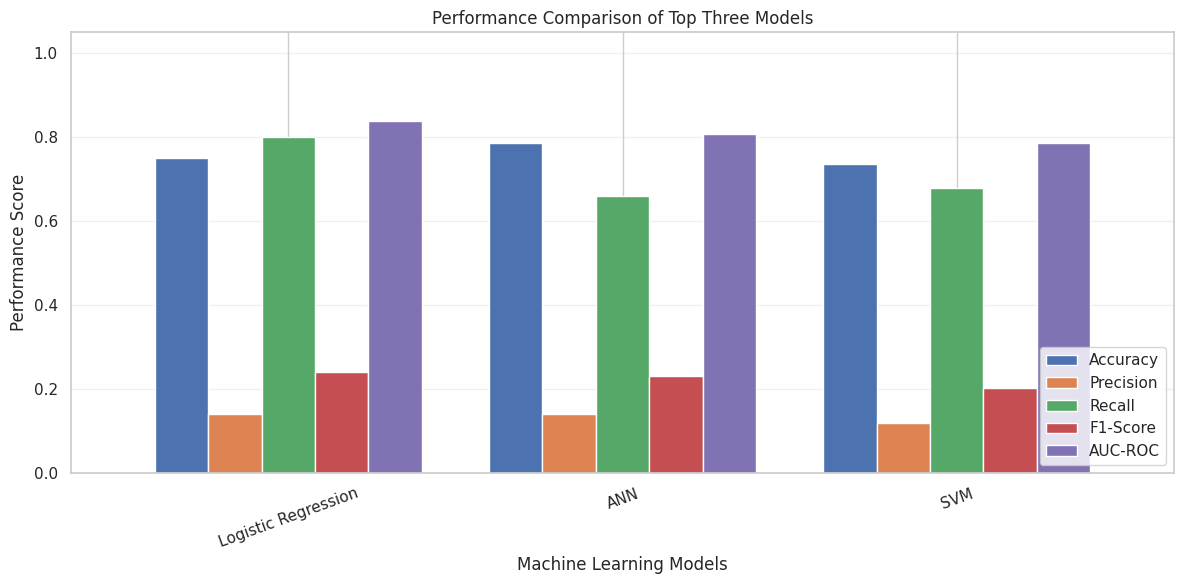

In [15]:
# ==========================================================
# TOP THREE MODEL COMPARISON GRAPH
# ==========================================================

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC-ROC"
]

top_three[comparison_metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Top Three Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Top_Three_Model_Comparison.png",
    dpi=300
)

plt.show()

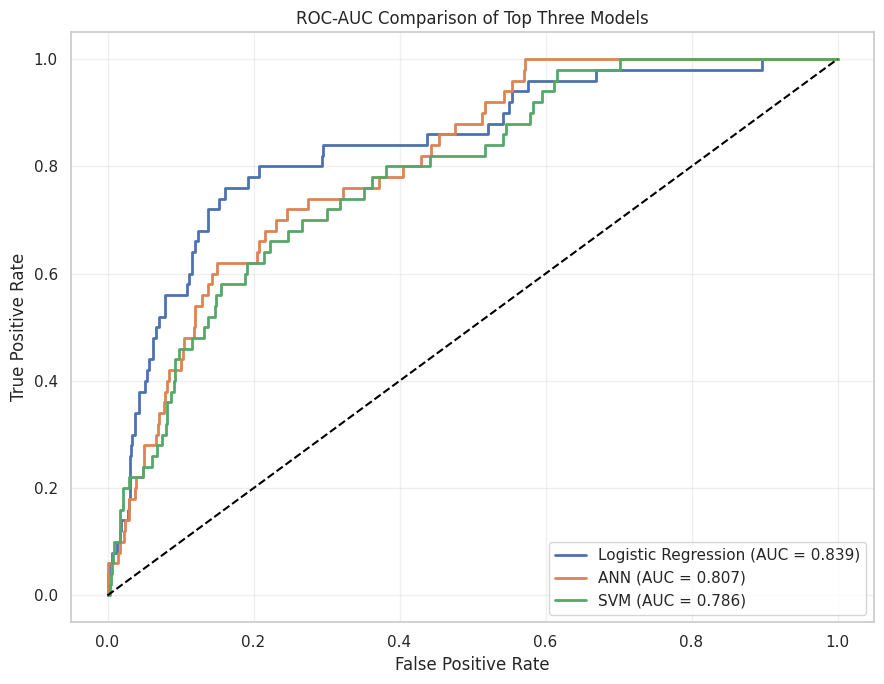

In [16]:
# ==========================================================
# ROC CURVE OF TOP THREE MODELS
# ==========================================================

plt.figure(figsize=(9, 7))

for name in top_three.index:

    pred, prob = models[name]

    fpr, tpr, _ = roc_curve(
        y_test,
        prob
    )

    auc_value = roc_auc_score(
        y_test,
        prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="black"
)

plt.title("ROC-AUC Comparison of Top Three Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Top_Three_ROC_Curve.png",
    dpi=300
)

plt.show()

In [17]:
# ==========================================================
# FINAL COMPARATIVE RESULTS
# ==========================================================

print("\n==============================================")
print("       FINAL STROKE PREDICTION RESULTS")
print("==============================================")

print("\n1. PERFORMANCE OF ALL FIVE MODELS")

display(results_df.round(4))

print("\n2. TOP THREE SELECTED MODELS")

display(top_three.round(4))

print("\n3. BEST PERFORMING MODEL")

print("Model Name:", top_three.index[0])

print(
    "Ranking Score:",
    round(top_three.iloc[0]["Ranking Score"], 4)
)

print("\nExperiment completed successfully!")


       FINAL STROKE PREDICTION RESULTS

1. PERFORMANCE OF ALL FIVE MODELS


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Strokes Found,Non-Strokes Found,Ranking Score
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387,40,728,0.6435
Decision Tree,0.7613,0.1057,0.52,0.1757,0.6727,26,752,0.4625
Random Forest,0.9501,0.0000,0.00,0.0000,0.7904,0,971,0.2371
SVM,0.7358,0.1181,0.68,0.2012,0.7856,34,718,0.5680
ANN,0.7857,0.1404,0.66,0.2316,0.8066,33,770,0.5755



2. TOP THREE SELECTED MODELS


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Strokes Found,Non-Strokes Found,Ranking Score
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387,40,728,0.6435
ANN,0.7857,0.1404,0.66,0.2316,0.8066,33,770,0.5755
SVM,0.7358,0.1181,0.68,0.2012,0.7856,34,718,0.5680



3. BEST PERFORMING MODEL
Model Name: Logistic Regression
Ranking Score: 0.6435

Experiment completed successfully!


In [18]:
import zipfile
from google.colab import files

output_files = [
    "model_performance_results.csv",
    "top_three_models.csv",
    "Combined_ROC_Curve.png",
    "Top_Three_Model_Comparison.png",
    "Top_Three_ROC_Curve.png"
]

# Add confusion matrices
for name in models:
    output_files.append(
        "Confusion_Matrix_" +
        name.replace(" ", "_") +
        ".png"
    )

with zipfile.ZipFile(
    "Stroke_Prediction_Results.zip",
    "w"
) as zip_file:

    for filename in output_files:

        if os.path.exists(filename):
            zip_file.write(filename)

files.download("Stroke_Prediction_Results.zip")

print("All results downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All results downloaded successfully!
